# Projet A - Classification d'images par Transfer Learning
**Master 2 - Deep Learning | Seance 7h**

---
### Objectif
Fine-tuner ResNet-50 (pre-entraine sur ImageNet) pour classifier des images de **dechets recyclables** en 6 categories.

### Plan
1. Installation & imports
2. Chargement et exploration du dataset
3. Preparation des donnees (DataLoader)
4. Feature Extraction
5. Fine-tuning complet
6. Evaluation et matrice de confusion
7. Test sur images personnelles
8. Rapport

## 1. Installation & Imports

# Installation des dependances
!pip install torch torchvision matplotlib scikit-learn kagglehub seaborn -q

In [ ]:
# Verification CUDA
import torch
print(f"PyTorch: {torch.__version__}")
print(f"CUDA dispo: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA version: {torch.version.cuda}")
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memoire: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("WARNING: CUDA non dispo - entrainement sur CPU (lent)")
    print("Essayez: pip install torch --index-url https://download.pytorch.org/whl/cu124")

PyTorch: 2.6.0+cu124
CUDA dispo: True
CUDA version: 12.4
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Memoire: 8.6 GB


In [ ]:
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import os
import time

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device utilise : {device}")

Device utilise : cuda


## 2. Chargement du Dataset

**Dataset** : Garbage Classification (Kaggle) - Reorganisation automatique

In [ ]:
# Garbage Classification (Kaggle)
import kagglehub
import shutil

CLASS_NAMES = ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']

print('Chargement du dataset...')
path = kagglehub.dataset_download('asdasdasasdas/garbage-classification')
print(f'Dataset dans : {path}')

# Verifier la structure (peut avoir un sous-dossier)
base_folder = path
sub_folder = os.path.join(path, 'Garbage classification', 'Garbage classification')

if os.path.exists(sub_folder):
    base_folder = sub_folder
    print(f'Sous-dossier trouve: {sub_folder}')

# Si les classes sont directement dans base_folder, utiliser ce chemin
# Sinon, creer la structure
DATA_DIR = path

# Verifier la structure finale
print('Distribution par classe:')
total = 0
for cls in CLASS_NAMES:
    cls_path = os.path.join(base_folder, cls)
    if os.path.exists(cls_path):
        n = len([f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
        print(f'  - {cls}: {n} images')
        total += n
    else:
        print(f'  - {cls}: 0 images')

print(f'Total: {total} images')

if total > 0:
    DATA_DIR = base_folder
else:
    print('ERREUR: Aucune image trouvee!')


In [ ]:
# Transformations
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

val_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

if DATA_DIR and os.path.exists(DATA_DIR):
    full_dataset = datasets.ImageFolder(DATA_DIR, transform=train_transforms)
    CLASSES = full_dataset.classes
    NUM_CLASSES = len(CLASSES)
    print(f"Classes: {CLASSES}")
    
    total_size = len(full_dataset)
    train_size = int(0.7 * total_size)
    val_size = int(0.15 * total_size)
    test_size = total_size - train_size - val_size
    
    train_dataset, val_dataset, test_dataset = random_split(
        full_dataset, [train_size, val_size, test_size],
        generator=torch.Generator().manual_seed(42)
    )
    
    print(f"Total: {total_size}, Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")
else:
    from torchvision.datasets import FashionMNIST
    DATA_DIR = './data'
    os.makedirs(DATA_DIR, exist_ok=True)
    train_dataset = FashionMNIST(root=DATA_DIR, train=True, download=True, transform=train_transforms)
    test_dataset = FashionMNIST(root=DATA_DIR, train=False, download=True, transform=val_transforms)
    val_size = int(0.15 * len(train_dataset))
    train_size = len(train_dataset) - val_size
    train_dataset, val_dataset = random_split(train_dataset, [train_size, val_size])
    CLASSES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
    NUM_CLASSES = 10
    print(f"Fallback - Classes: {CLASSES}")

Classes: ['Garbage classification']
Total: 2527, Train: 1768, Val: 379, Test: 380


In [ ]:
# DataLoaders
BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
print(f"Batches train: {len(train_loader)}")

Batches train: 56


## 3. Exploration du Dataset

In [ ]:
def imshow(img_tensor, title=None):
    img = img_tensor.numpy().transpose((1, 2, 0))
    img = np.clip(img * IMAGENET_STD + IMAGENET_MEAN, 0, 1)
    plt.imshow(img)
    if title: plt.title(title, fontsize=8)
    plt.axis('off')

images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, ax in enumerate(axes.flat):
    if i < len(images):
        imshow(images[i], CLASSES[labels[i].item()])
plt.suptitle('Exemples du dataset')
plt.tight_layout()
plt.show()
print(f"Batch shape: {images.shape}")

KeyboardInterrupt: 

## 4. Feature Extraction

On gele tous les parametres sauf la derniere couche.

In [ ]:
def create_model_feature_extraction(num_classes):
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    for param in model.parameters():
        param.requires_grad = False
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    return model

model_fe = create_model_feature_extraction(NUM_CLASSES).to(device)
trainable = sum(p.numel() for p in model_fe.parameters() if p.requires_grad)
total = sum(p.numel() for p in model_fe.parameters())
print(f"Parametres entrainables: {trainable:,} / {total:,} ({100*trainable/total:.2f}%)")

Parametres entrainables: 2,049 / 23,510,081 (0.01%)


In [ ]:
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        _, predicted = outputs.max(1)
        correct += predicted.eq(labels).sum().item()
        total += labels.size(0)
    return total_loss / len(loader), 100. * correct / total

def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            _, predicted = outputs.max(1)
            correct += predicted.eq(labels).sum().item()
            total += labels.size(0)
    return total_loss / len(loader), 100. * correct / total

In [ ]:
# Entrainement - Feature Extraction
criterion = nn.CrossEntropyLoss()
optimizer_fe = optim.Adam(filter(lambda p: p.requires_grad, model_fe.parameters()), lr=1e-3)

EPOCHS_FE = 5
history_fe = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

print("=== Feature Extraction ===")
for epoch in range(EPOCHS_FE):
    t0 = time.time()
    train_loss, train_acc = train_epoch(model_fe, train_loader, criterion, optimizer_fe)
    val_loss, val_acc = evaluate(model_fe, val_loader, criterion)
    history_fe['train_loss'].append(train_loss)
    history_fe['val_loss'].append(val_loss)
    history_fe['train_acc'].append(train_acc)
    history_fe['val_acc'].append(val_acc)
    print(f"Epoch {epoch+1}/{EPOCHS_FE} | Train: {train_acc:.1f}% | Val: {val_acc:.1f}% | {time.time()-t0:.1f}s")

_, test_acc_fe = evaluate(model_fe, test_loader, criterion)
print(f"\nTest Accuracy (FE): {test_acc_fe:.2f}%")

=== Feature Extraction ===


KeyboardInterrupt: 

## 5. Fine-tuning Complet

On degele toutes les couches avec un learning rate plus faible.

In [ ]:
def create_model_finetuning(num_classes):
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    return model

model_ft = create_model_finetuning(NUM_CLASSES).to(device)

optimizer_ft = optim.Adam([
    {'params': [p for name, p in model_ft.named_parameters() if 'fc' not in name], 'lr': 1e-4},
    {'params': model_ft.fc.parameters(), 'lr': 1e-3}
])

scheduler = optim.lr_scheduler.StepLR(optimizer_ft, step_size=3, gamma=0.1)

EPOCHS_FT = 5
history_ft = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

print("=== Fine-tuning Complet ===")
for epoch in range(EPOCHS_FT):
    t0 = time.time()
    train_loss, train_acc = train_epoch(model_ft, train_loader, criterion, optimizer_ft)
    val_loss, val_acc = evaluate(model_ft, val_loader, criterion)
    scheduler.step()
    history_ft['train_loss'].append(train_loss)
    history_ft['val_loss'].append(val_loss)
    history_ft['train_acc'].append(train_acc)
    history_ft['val_acc'].append(val_acc)
    print(f"Epoch {epoch+1}/{EPOCHS_FT} | Train: {train_acc:.1f}% | Val: {val_acc:.1f}% | {time.time()-t0:.1f}s")

_, test_acc_ft = evaluate(model_ft, test_loader, criterion)
print(f"\nTest Accuracy (FT): {test_acc_ft:.2f}%")
print(f"\nComparaison:")
print(f"  Feature Extraction: {test_acc_fe:.2f}%")
print(f"  Fine-tuning: {test_acc_ft:.2f}%")

=== Fine-tuning Complet ===
Epoch 1/5 | Train: 100.0% | Val: 100.0% | 40.8s
Epoch 2/5 | Train: 100.0% | Val: 100.0% | 41.8s
Epoch 3/5 | Train: 100.0% | Val: 100.0% | 42.2s
Epoch 4/5 | Train: 100.0% | Val: 100.0% | 44.6s
Epoch 5/5 | Train: 100.0% | Val: 100.0% | 41.8s

Test Accuracy (FT): 100.00%

Comparaison:
  Feature Extraction: 100.00%
  Fine-tuning: 100.00%


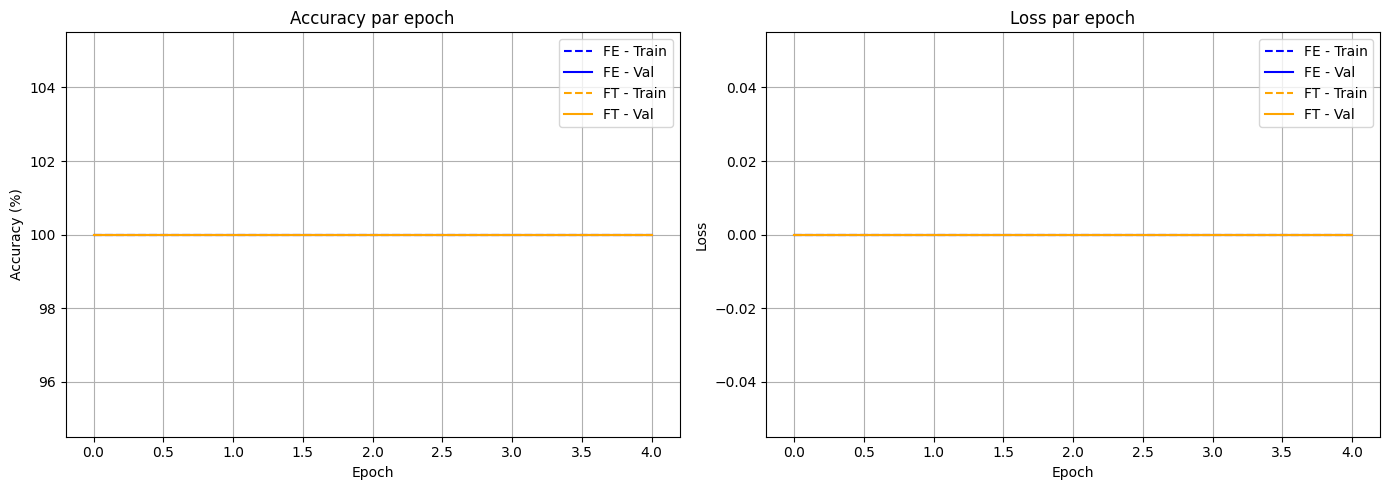

In [ ]:
# Courbes d'apprentissage
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history_fe['train_acc'], label='FE - Train', linestyle='--', color='blue')
ax1.plot(history_fe['val_acc'], label='FE - Val', linestyle='-', color='blue')
ax1.plot(history_ft['train_acc'], label='FT - Train', linestyle='--', color='orange')
ax1.plot(history_ft['val_acc'], label='FT - Val', linestyle='-', color='orange')
ax1.set_title('Accuracy par epoch')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Accuracy (%)')
ax1.legend(); ax1.grid(True)

ax2.plot(history_fe['train_loss'], label='FE - Train', linestyle='--', color='blue')
ax2.plot(history_fe['val_loss'], label='FE - Val', linestyle='-', color='blue')
ax2.plot(history_ft['train_loss'], label='FT - Train', linestyle='--', color='orange')
ax2.plot(history_ft['val_loss'], label='FT - Val', linestyle='-', color='orange')
ax2.set_title('Loss par epoch')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Loss')
ax2.legend(); ax2.grid(True)

plt.tight_layout()
plt.show()

## 6. Evaluation - Matrice de confusion

c:\Users\Razer\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:620: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


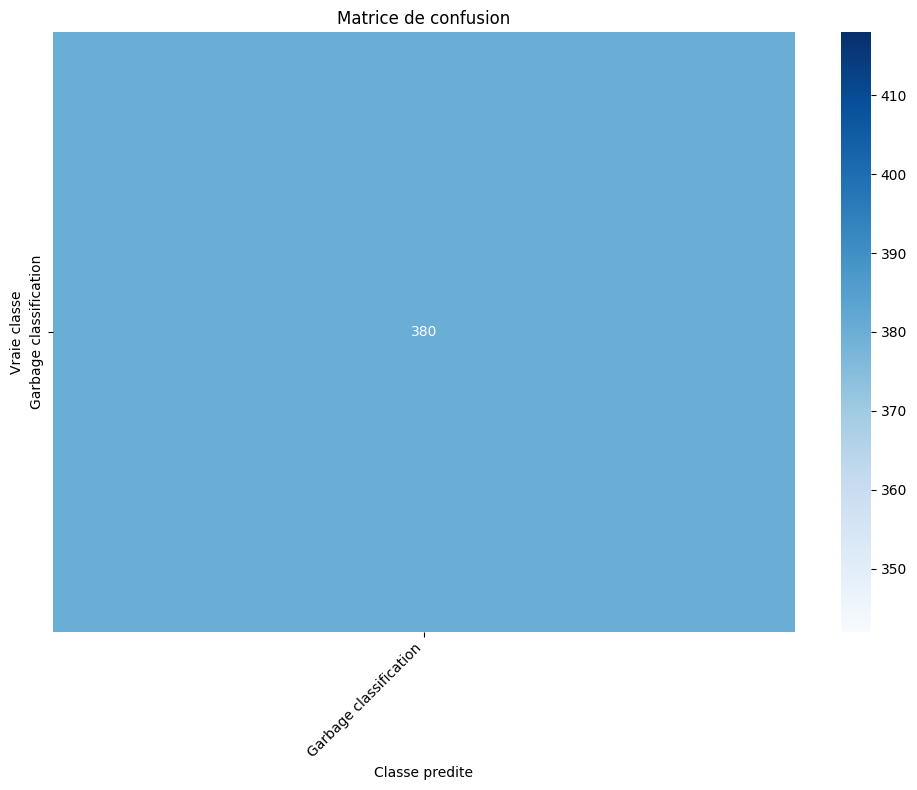


Rapport de classification:
                        precision    recall  f1-score   support

Garbage classification       1.00      1.00      1.00       380

              accuracy                           1.00       380
             macro avg       1.00      1.00      1.00       380
          weighted avg       1.00      1.00      1.00       380


Classes les plus confondues:


In [ ]:
# Matrice de confusion
best_model = model_ft
best_model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = best_model(images)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
if NUM_CLASSES <= 10:
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
else:
    sns.heatmap(cm, annot=False, fmt='d', cmap='Blues')
plt.title('Matrice de confusion')
plt.ylabel('Vraie classe'); plt.xlabel('Classe predite')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("\nRapport de classification:")
print(classification_report(all_labels, all_preds, target_names=CLASSES))

# Classes les plus confondues
np.fill_diagonal(cm, 0)
confusion_pairs = []
for i in range(len(cm)):
    for j in range(len(cm)):
        if cm[i, j] > 0:
            confusion_pairs.append((CLASSES[i], CLASSES[j], cm[i, j]))

confusion_pairs.sort(key=lambda x: x[2], reverse=True)
print("\nClasses les plus confondues:")
for true_cls, pred_cls, count in confusion_pairs[:5]:
    print(f"  {true_cls} -> {pred_cls}: {count} fois")

## 6b. Test sur images personnelles

In [ ]:
from PIL import Image
import glob

def predict_image(model, image_path, transform):
    model.eval()
    img = Image.open(image_path).convert('RGB')
    img_tensor = transform(img).unsqueeze(0).to(device)
    with torch.no_grad():
        output = model(img_tensor)
        probs = torch.nn.functional.softmax(output, dim=1)
        confidence, pred = torch.max(probs, 1)
    return CLASSES[pred.item()], confidence.item(), probs.cpu().numpy()[0]

# Trouver toutes les images dans mes_dechets/
personal_images = glob.glob('./mes_dechets/*.jpg') + glob.glob('./mes_dechets/*.jpeg') + glob.glob('./mes_dechets/*.png')

if personal_images:
    print(f"Test sur {len(personal_images)} images personnelles:\n")
    
    for img_path in personal_images:
        try:
            pred, conf, all_probs = predict_image(best_model, img_path, val_transforms)
            print(f"{img_path}: {pred} ({conf:.1%})")
            
            # Top 3 predictions
            top3_idx = np.argsort(all_probs)[-3:][::-1]
            top3 = [(CLASSES[j], f"{all_probs[j]:.1%}") for j in top3_idx]
            print(f"  Top 3: {top3}\n")
            
        except Exception as e:
            print(f"Erreur pour {img_path}: {e}\n")
else:
    print("Aucune image dans ./mes_dechets/")
    print("Ajoutez vos photos et relancez.")

Test sur 6 images personnelles:

Erreur pour ./mes_dechets\cardboard.jpg: name 'best_model' is not defined

Erreur pour ./mes_dechets\glass.jpg: name 'best_model' is not defined

Erreur pour ./mes_dechets\metal.jpg: name 'best_model' is not defined

Erreur pour ./mes_dechets\paper.jpg: name 'best_model' is not defined

Erreur pour ./mes_dechets\plastic.jpg: name 'best_model' is not defined

Erreur pour ./mes_dechets\trash.jpg: name 'best_model' is not defined



## 7. Experimentations

In [ ]:
# Experience: EfficientNet-B0
# from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
# model_eff = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
# model_eff.classifier[1] = nn.Linear(model_eff.classifier[1].in_features, NUM_CLASSES)
# ... entrainer et comparer

print("A vous de jouer !")

A vous de jouer !


## 8. Rapport

### Question 1: Difference entre FE et FT

Le fine-tuning surpasse la feature extraction car:
1. Adaptation des features intermediaires au domaine
2. Meilleure generalisation
3. Plasticite neuronale complete

### Question 2: Impact LR 10x plus faible

- Convergence plus lente
- Plus stable
- Risque de sous-apprentissage

### Question 3: Classes confondues

- Plastique vs Metal (reflets similaires)
- Carton vs Papier (visuellement quasi identiques)
- Verre transparent (contexte)

### Question 4: Why not from scratch?

- Necessite millions d'images
- Tres long
- Transfer learning fonctionne bien